In [1]:
from circuit_benchmarks import MB_Experiment
from selene_sim import DepolarizingErrorModel, Stim, Quest
from pecos_selene import qsystem_model_alpha # requires pecos_selene

In [2]:
# select parameters and build experiment

n_qubits = 98
seq_lengths = [4, 8, 12] # half of circuit depth
seq_reps = 5 # number of repetitions of each sequence length
filename = 'exp_MB_example.p'

exp = MB_Experiment(n_qubits, seq_lengths, seq_reps)

# additional options
#exp.options['SQ_type'] = 'Clifford' # Clifford by default or 'Clifford+T'
#exp.options['Pauli_twirl'] = True # True by default
#exp.options['permute'] = True # True by default
#exp.options['measure_leaked'] = True # False by default.

exp.add_settings()

In [ ]:
# or load an existing experiment from working directory

filename = 'exp_MB_example.p'
exp = MB_Experiment.load(filename)

Having setup our MB experiment, we can now either simulate using a local simulator or submit to a hardware or emulator backend.

### Run local simulation using Selene

In [3]:
# setup simple error model

error_model = DepolarizingErrorModel(
    random_seed=1234,
    # single qubit gate error rate
    #p_1q=3e-5,
    # two qubit gate error rate
    p_2q=1e-3,
    # set state preparation and measurement error rates to 0
    p_meas=0,
    p_init=0,
)

In [3]:
# Or use hardware realistic error model

error_model = qsystem_model_alpha(random_seed=123)
error_model.coherent_dephasing = False

c:\Users\Karl.Mayer\myenv\Lib\site-packages\pecos_selene\error_models\named.py:28: UserWarning: 


* Crosstalk includes no unleak term, but is otherwise fairly realistic.

* Leakage and memory error are implemented as in H1/H2, but it is expected these will be different in Helios.

* Calibration of the noise parameter values for Helios is still ongoing.
  warnings.warn(msg)


In [4]:
# simulate experiment

shots = 100
simulator = Stim() # use Quest() if SQ_type = 'Clifford+T'

exp.sim(shots, error_model=error_model, simulator=simulator)

Simulating ...
1/15 circuits complete
2/15 circuits complete
3/15 circuits complete
4/15 circuits complete
5/15 circuits complete
6/15 circuits complete
7/15 circuits complete
8/15 circuits complete
9/15 circuits complete
10/15 circuits complete
11/15 circuits complete
12/15 circuits complete
13/15 circuits complete
14/15 circuits complete
15/15 circuits complete


### Submit to Quantinuum Hardware or Emulator backend using Nexus

In [3]:
# Choose domain and login to Nexus

import qnexus

### uncomment lines below if submitting to QA ###
#from qnexus.config import CONFIG
#CONFIG.domain = "qa.myqos.com"

qnexus.login_with_credentials()

Enter your Nexus email:  karl.mayer@quantinuum.com
Enter your Nexus password:  ········


✅ Successfully logged in as karl.mayer@quantinuum.com.


In [4]:
# choose nexus project and setup quantinuum backend config

project = qnexus.projects.get_or_create(name='MB-example-project')
qnexus.context.set_active_project(project)

backend_config = qnexus.QuantinuumConfig(device_name='Helios-1E', simulator='stabilizer', max_cost=1000000)

In [5]:
# submit experiment. Returns a qnexus ExecuteJobRef

shots = 100

execute_job_ref = exp.submit(shots, backend_config)

Experiment saved! experiment.p


In [8]:
# inspect status of the execution job

qnexus.jobs.status(execute_job_ref)

JobStatus(status=<JobStatusEnum.ERROR: 'ERROR'>, message='Circuit has encountered an error.', error_detail="<class 'redis.exceptions.TimeoutError'>: Timeout connecting to server", completed_time=None, queued_time=None, submitted_time=datetime.datetime(2025, 8, 28, 18, 35, 18, 922113, tzinfo=datetime.timezone.utc), running_time=None, cancelled_time=None, error_time=datetime.datetime(2025, 8, 28, 18, 38, 8, 615322, tzinfo=datetime.timezone.utc), queue_position=None)

In [ ]:
# retrieve results

exp.retrieve(execute_job_ref)

### Analyze experiment results

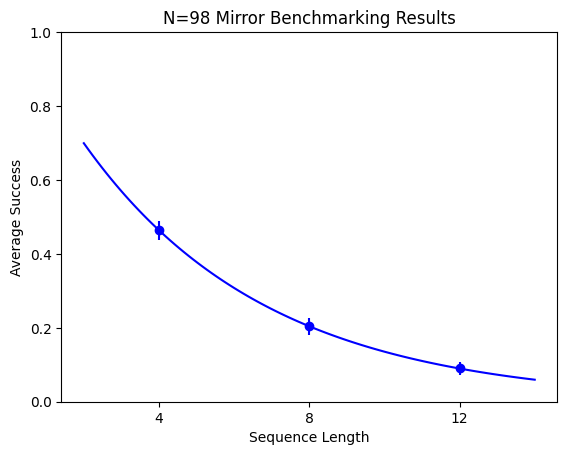

Success Probabilities
----------------------
4: 0.464 +/- 0.0257
8: 0.204 +/- 0.023
12: 0.09 +/- 0.018

Max circuit depth with survival > 2/3: 6

TQ Average Fidelity (for depolarizing error) = 0.9983 +/- 0.0002
Experiment saved! experiment.p


In [5]:
exp.analyze_results(ylim=(0,1))

In [ ]:
# save experiment object to working directory

exp.save()